# Simulating Planetary Orbits

In this notebook im going to use Euler's method [1] to simulate the planet's orbits

Let consider the Earth’s orbit first!

In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from template_python import force,move_planet,trajectory,plot_trajectory
from phas0007anim_v2 import animate_trajectories_2d

In [3]:
G       = 6.6743e-11 # gravitational constant [m^3 kg^-1 s^-2]
YEAR    = 3.154e7    # one year in seconds
M_SOLAR = 1.989e30   # solar mass [kg]
AU      = 1.496e11   # one astronomical unit (mean orbital radius of Earth) [m]
P_SOLAR = np.array([0,0])  # position of solar [m]

In [4]:
# Calculate orbital speed of Earth [m/s] assuming circular orbit
v_earth = np.sqrt(G*M_SOLAR/AU)
# Initial conditions of Earth
pos_earth = np.array([AU, 0])       # position (x,y) [m]
vel_earth = np.array([0,v_earth])   # velocity (vx,vy) [m/s]

dt=YEAR/10000

traj_EARTH=trajectory(pos_earth, vel_earth, M_SOLAR, dt, 5*YEAR)

#code adapt from Template notebook for final assignment preparatory task

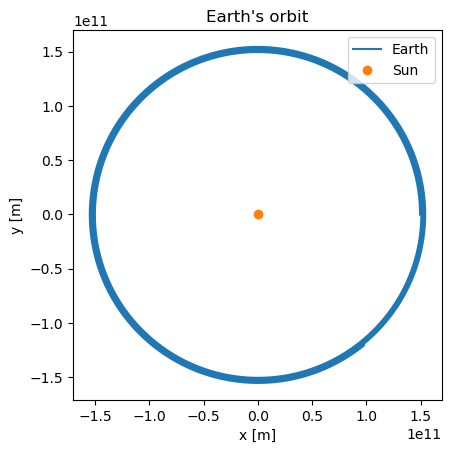

In [5]:
#plot the graph
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_EARTH
plot_trajectory(x_earth, y_earth,label="Earth")
plt.plot(0, 0, 'o', label='Sun')
plt.legend(loc='upper right');

#code adapt from Template notebook for final assignment preparatory task

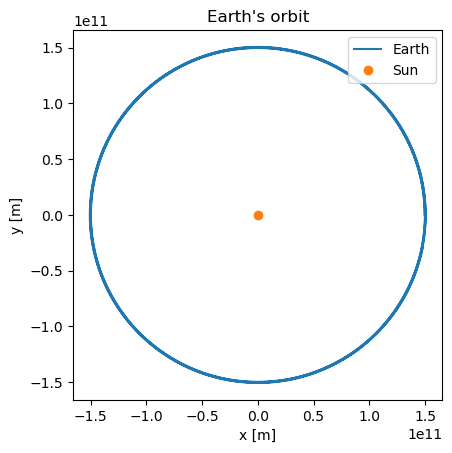

In [6]:
#smaller dt
dt=YEAR/50000
traj_EARTH=trajectory(pos_earth, vel_earth, M_SOLAR, dt, 5*YEAR)

#plot the graph
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_EARTH
plot_trajectory(x_earth, y_earth,label='Earth')
plt.plot(0, 0, 'o', label='Sun')
plt.legend(loc='upper right');

It is obvious that as the dt decrease (from YEAR/10000 to YEAR/50000), the thickness of the five years trajectory decrease. This is due to the more accurate calculation. In Euler's method, the less the dt, the less the uncertainty. The uncertainty in dt=YEAR/50000 is smaller, therefore the simulate trajectory during this five years period is more similar, so its trajectory is thinner, which means more accurate.

I think YEAR/50000 is a reasonable dt. Compare with dt=YEAR/10000, the start point and end point of its trajectory is closer, and it doesn't require a lot of computing power to calculate. If we choose a smaller dt, such as YEAR/100000, it requires the computer to take a long time to simulate. If we choose a larger dt, the time saved is negligible.

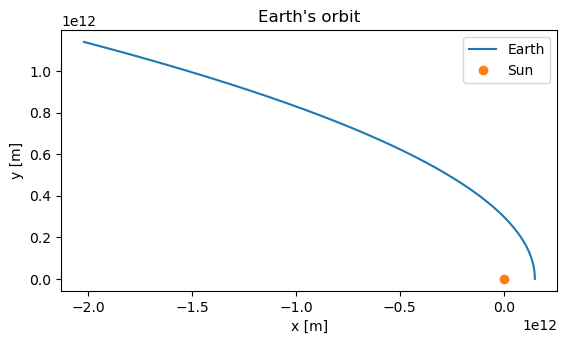

In [7]:
#increase the initial velocity of Earth to escape velocity
vel_new = np.array([0,np.sqrt(2*G*M_SOLAR/AU)])
traj_EARTH=trajectory(pos_earth, vel_new, M_SOLAR, dt, 5*YEAR)

#plot the graph
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_EARTH
plot_trajectory(x_earth, y_earth,label='Earth')
plt.plot(0, 0, 'o', label='Sun')
plt.legend(loc='upper right');

We can see that when the initial speed of Earth is increased to the escape velocity, the trajectory changes from a closed ellipse to a parabola.

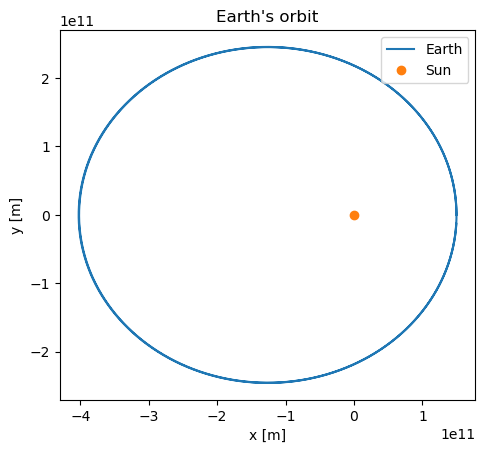

In [8]:
#increase the initial speed to values intermediate between the actual value and the escape velocity
vel_new = np.array([0,(np.sqrt(2*G*M_SOLAR/AU)-v_earth)/2+v_earth])
traj_EARTH=trajectory(pos_earth, vel_new, M_SOLAR, dt, 5*YEAR)

#plot the graph
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_EARTH
plot_trajectory(x_earth, y_earth,label='Earth')
plt.plot(0, 0, 'o', label='Sun')
plt.legend(loc='upper right');

We can see that when the initial speed of Earth is increased to value intermediate between the actual value and the escape velocity, its trajectory become a high eccentricity elliptical orbit, and its period is also increase.

In [ ]:
#increase the initial velocity of Earth to values more than escape velocity
vel_new = np.array([0,np.sqrt(2*G*M_SOLAR/AU)*1.5])
traj_EARTH=trajectory(pos_earth, vel_new, M_SOLAR, dt, 5*YEAR)

#plot the graph
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_EARTH
plot_trajectory(x_earth, y_earth,label='Earth')
plt.plot(0, 0, 'o', label='Sun')
plt.legend(loc='upper right');

We can see that the higher the speed, the higher the eccentricity, and the straighter the trajectory.

In [ ]:
#decrease the initial velocity of Earth
vel_new = vel_earth/2
traj_EARTH=trajectory(pos_earth, vel_new, M_SOLAR, dt, 5*YEAR)

#plot the graph
plt.figure()
plt.title("Earth's orbit")
x_earth, y_earth = traj_EARTH
plot_trajectory(x_earth, y_earth,label='Earth')
plt.plot(0, 0, 'o', label='Sun')
plt.legend(loc='upper right');

We can see that when speed decrease, its trajectory is still elliptical, but the eccentricity decrease, and the Earth is falling to the Sun.

The accuracy of the calculation affects a lots when the eccentricity is high, because the change in velocity near perihelion is extremily high, so its require smaller dt. The accuracy is also important when the velocity is near the escape velocity, because this directly determine whether the Earth can escape. 

Now, lets consider two interacting planets!

In [ ]:
#define some important constants
m_earth = 5.972e24  # Earth mass [kg]
m_venus = 4.867e24  # Venus mass [kg]
r_venus = 0.723*AU  # mean orbital radius of Venus [m]
# Initial conditions of Venus
pos_venus = np.array([r_venus, 0])
vel_venus = np.array([0,np.sqrt(G*M_SOLAR/r_venus)])

In [ ]:
def move_two_planets(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,m_venus,M_SOLAR,dt):
    '''
    Calculate motion of Earth and Venus in both gravitational fields, using Euler's method.

    Input:
    pos_earth: initial position vector of Earth
    vel_earth: initial velocity vector of Earth
    pos_venus: initial position vector of Venus
    vel_venus: initial velocity vector of Venus
    m_earth  : mass of Earth
    m_venus  : mass of Venus
    M_SOLAR  : mass of Sun
    dt       : time step

    Output:
    new_pos_earth : position vector of Earth at end of time step
    new_vel_earth : velocity vector of Earth at end of time step
    new_pos_venus : position vector of Venus at end of time step
    new_vel_venus : velocity vector of Venus at end of time step

    '''

    #position of Sun
    pos_sun=np.array([0,0])
    
    #force on Earth
    force_sun_on_earth=force(pos_sun,pos_earth,M_SOLAR,m_earth)
    force_venus_on_earth=force(pos_venus,pos_earth,m_venus,m_earth)
    total_earth=force_sun_on_earth+force_venus_on_earth
    
    #force on Venus
    force_sun_on_venus=force(pos_sun,pos_venus,M_SOLAR,m_venus)
    force_earth_on_venus=force(pos_earth,pos_venus,m_earth,m_venus)
    total_venus=force_sun_on_venus+force_earth_on_venus

    #calculate both accelerations
    acc_earth=total_earth/m_earth
    acc_venus=total_venus/m_venus

    #Euler method
    new_vel_earth=vel_earth+acc_earth*dt
    new_vel_venus=vel_venus+acc_venus*dt
    
    new_pos_earth=pos_earth+vel_earth*dt
    new_pos_venus=pos_venus+vel_venus*dt
    
    return new_pos_earth,new_vel_earth,new_pos_venus,new_vel_venus

In [ ]:
def trajectories(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,m_venus,M_SOLAR,dt,t_max):
    '''
    Calculate trajectories of Earth and Venus from given starting position in two dimensions, using Euler's method.

    Input:
    pos_earth: initial position vector of Earth
    vel_earth: initial velocity vector of Earth
    pos_venus: initial position vector of Venus
    vel_venus: initial velocity vector of Venus
    m_earth  : mass of Earth
    m_venus  : mass of Venus
    M_SOLAR  : mass of Sun
    dt       : time step
    t_max    : duration of calculated motion

    Output:
    traj_earth: trajectory of Earth
    traj_venus: trajectory of Venus

    '''
    #initial position of Earth and Venus
    x,y=pos_earth
    earth_x,earth_y=[x],[y]
    x,y=pos_venus
    venus_x,venus_y=[x],[y]
    t=0

    #calculate new position and velocity
    while t<=t_max:
        t+=dt
        pos_earth,vel_earth,pos_venus,vel_venus=move_two_planets(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,m_venus,M_SOLAR,dt)
        temp_x,temp_y=pos_earth
        earth_x.append(temp_x)
        earth_y.append(temp_y)
        temp_x,temp_y=pos_venus
        venus_x.append(temp_x)
        venus_y.append(temp_y)


    traj_earth=np.array([earth_x, earth_y])
    traj_venus=np.array([venus_x, venus_y])
    
    return traj_earth,traj_venus

In [ ]:
t_max=5*YEAR
dt=YEAR/50000
traj_earth,traj_venus=trajectories(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,m_venus,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth and Venus")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

In [ ]:
#the mass of Venus times ten
new_m_venus=m_venus*10

traj_earth,traj_venus=trajectories(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,new_m_venus,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth and Venus")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

In [ ]:
#the mass of Venus times 100
new_m_venus=m_venus*100

traj_earth,traj_venus=trajectories(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,new_m_venus,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth and Venus")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

In [ ]:
#the mass of Venus times 1000
new_m_venus=m_venus*1000

traj_earth,traj_venus=trajectories(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,new_m_venus,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth and Venus")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

In [ ]:
#the mass of Venus times 10000
new_m_venus=m_venus*10000

traj_earth,traj_venus=trajectories(pos_earth,vel_earth,pos_venus,vel_venus,m_earth,new_m_venus,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth and Venus")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

When the mass of Venus times 10000, it makes a noticable difference to Earth's orbit. This phenomenon is shown on the graphs above.

In [ ]:
ani_trajectories=[traj_earth,traj_venus]
animate_trajectories_2d(ani_trajectories,20,5)

The animation above shows the changes of Earth's orbit when the mass of Venus times 10000. 
I find that the eccentricity and period of the Earth increase, this may due to the increase in Venus's gravitation force. If the mass of Venus doesn't times 10000, its effect is negligible, but now, when the Earth moves in the front of the Venus, the Venus's gravitational field pull Earth, which decrease the velocity of the Earth, and Earth loss energy, vice versa. But this is an elliptical orbit, so for Earth, the loss in energy is greater than gain in energy, so its period increase.

In [ ]:
m_jupyter=1.898e27
r_jupyter=5.204*AU
pos_jupyter=np.array([r_jupyter,0])
vel_jupyter=np.array([0,np.sqrt(G*M_SOLAR/r_jupyter)])

In [ ]:
def move_three_planets(pos_earth,vel_earth,pos_venus,vel_venus,pos_jupyter,vel_jupyter,m_earth,m_venus,m_jupyter,M_SOLAR,dt):
    '''
    Calculate motion of Earth and Venus in both gravitational fields, using Euler's method.

    Input:
    pos_earth  : initial position vector of Earth
    vel_earth  : initial velocity vector of Earth
    pos_venus  : initial position vector of Venus
    vel_venus  : initial velocity vector of Venus
    pos_jupyter: initial position vector of Jupyter
    vel_jupyter: initial velocity vector of Jupyter
    m_earth    : mass of Earth
    m_venus    : mass of Venus
    m_jupyter  : mass of Jupyter
    M_SOLAR    : mass of Sun
    dt         : time step

    Output:
    new_pos_earth   : position vector of Earth at end of time step
    new_vel_earth   : velocity vector of Earth at end of time step
    new_pos_venus   : position vector of Venus at end of time step
    new_vel_venus   : velocity vector of Venus at end of time step
    new_pos_jupyter : position vector of Jupyter at end of time step
    new_vel_jupyter : velocity vector of Jupyter at end of time step

    '''

    #position of Sun
    pos_sun=np.array([0,0])
    
    #force on Earth
    force_sun_on_earth=force(pos_sun,pos_earth,M_SOLAR,m_earth)
    force_venus_on_earth=force(pos_venus,pos_earth,m_venus,m_earth)
    force_jupyter_on_earth=force(pos_jupyter,pos_earth,m_jupyter,m_earth)
    total_earth=force_sun_on_earth+force_venus_on_earth+force_jupyter_on_earth
    
    #force on Venus
    force_sun_on_venus=force(pos_sun,pos_venus,M_SOLAR,m_venus)
    force_earth_on_venus=force(pos_earth,pos_venus,m_earth,m_venus)
    force_jupyter_on_venus=force(pos_jupyter,pos_venus,m_jupyter,m_venus)
    total_venus=force_sun_on_venus+force_earth_on_venus+force_jupyter_on_venus

    #force on Jupyter
    force_sun_on_jupyter=force(pos_sun,pos_jupyter,M_SOLAR,m_jupyter)
    force_earth_on_jupyter=force(pos_earth,pos_jupyter,m_earth,m_jupyter)
    force_venus_on_jupyter=force(pos_venus,pos_jupyter,m_venus,m_jupyter)
    total_jupyter=force_sun_on_jupyter+force_earth_on_jupyter+force_venus_on_jupyter
    
    #calculate both accelerations
    acc_earth=total_earth/m_earth
    acc_venus=total_venus/m_venus
    acc_jupyter=total_jupyter/m_jupyter

    #Euler method
    new_vel_earth=vel_earth+acc_earth*dt
    new_vel_venus=vel_venus+acc_venus*dt
    new_vel_jupyter=vel_jupyter+acc_jupyter*dt
    
    new_pos_earth=pos_earth+vel_earth*dt
    new_pos_venus=pos_venus+vel_venus*dt
    new_pos_jupyter=pos_jupyter+vel_jupyter*dt

    
    return new_pos_earth,new_vel_earth,new_pos_venus,new_vel_venus,new_pos_jupyter,new_vel_jupyter

In [ ]:
def three_trajectories(pos_earth,vel_earth,pos_venus,vel_venus,pos_jupyter,vel_jupyter,m_earth,m_venus,m_jupyter,M_SOLAR,dt,t_max):
    '''
    Calculate trajectories of Earth and Venus from given starting position in two dimensions, using Euler's method.

    Input:
    pos_earth: initial position vector of Earth
    vel_earth: initial velocity vector of Earth
    pos_venus: initial position vector of Venus
    vel_venus: initial velocity vector of Venus
    pos_jupyter: initial position vector of Jupyter
    vel_jupyter: initial velocity vector of Jupyter
    m_earth  : mass of Earth
    m_venus  : mass of Venus
    m_jupyter  : mass of Jupyter
    M_SOLAR  : mass of Sun
    dt       : time step
    t_max    : duration of calculated motion

    Output:
    traj_earth: trajectory of Earth
    traj_venus: trajectory of Venus
    traj_jupyter: trajectory of Jupyter

    '''
    #initial position of Earth,Venus and Jupyter
    x,y=pos_earth
    earth_x,earth_y=[x],[y]
    x,y=pos_venus
    venus_x,venus_y=[x],[y]
    x,y=pos_jupyter
    jupyter_x,jupyter_y=[x],[y]
    t=0

    #calculate new position and velocity
    while t<=t_max:
        t+=dt
        pos_earth,vel_earth,pos_venus,vel_venus,pos_jupyter,vel_jupyter=move_three_planets(pos_earth,vel_earth,pos_venus,vel_venus,pos_jupyter,vel_jupyter,m_earth,m_venus,m_jupyter,M_SOLAR,dt)
        temp_x,temp_y=pos_earth
        earth_x.append(temp_x)
        earth_y.append(temp_y)
        temp_x,temp_y=pos_venus
        venus_x.append(temp_x)
        venus_y.append(temp_y)
        temp_x,temp_y=pos_jupyter
        jupyter_x.append(temp_x)
        jupyter_y.append(temp_y)


    traj_earth=np.array([earth_x, earth_y])
    traj_venus=np.array([venus_x, venus_y])
    traj_jupyter=np.array([jupyter_x, jupyter_y])
    
    return traj_earth,traj_venus,traj_jupyter

In [ ]:
t_max=5*YEAR
dt=YEAR/50000
traj_earth,traj_venus,traj_jupyter=three_trajectories(pos_earth,vel_earth,pos_venus,vel_venus,pos_jupyter,vel_jupyter,m_earth,m_venus,m_jupyter,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth,Venus and jupyter")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
x_jupyter,y_jupyter=traj_jupyter
plot_trajectory(x_jupyter,y_jupyter,label='jupyter')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

It is obvious that the period of jupyter is super long, this is because the square of the period is proportion to the cube of the radius.
now we increase the t_max to find the period of Jupyter

In [ ]:
t_max=12*YEAR
dt=YEAR/50000
traj_earth,traj_venus,traj_jupyter=three_trajectories(pos_earth,vel_earth,pos_venus,vel_venus,pos_jupyter,vel_jupyter,m_earth,m_venus,m_jupyter,M_SOLAR,dt,t_max)

plt.figure()
plt.title("orbits of Earth,Venus and jupyter")
x_earth,y_earth=traj_earth
plot_trajectory(x_earth,y_earth,label='Earth')
x_venus,y_venus=traj_venus
plot_trajectory(x_venus,y_venus,label='Venus')
x_jupyter,y_jupyter=traj_jupyter
plot_trajectory(x_jupyter,y_jupyter,label='jupyter')
plt.plot(0, 0,'o',label='Sun')
plt.legend(loc='upper right');

The period of Jupyter is approximately 12 years.

we can also see that Jupiter's gravity has little effect on Earth's orbit. This is because the distance between the Earth and the Jupyter is too long, and also the mass of Jupyter is not big enough. But there is still a small effect on Earth's orbit, but that could takes about 100 years to see it significantly.

## References:

1: https://zh.wikipedia.org/wiki/Euler_method